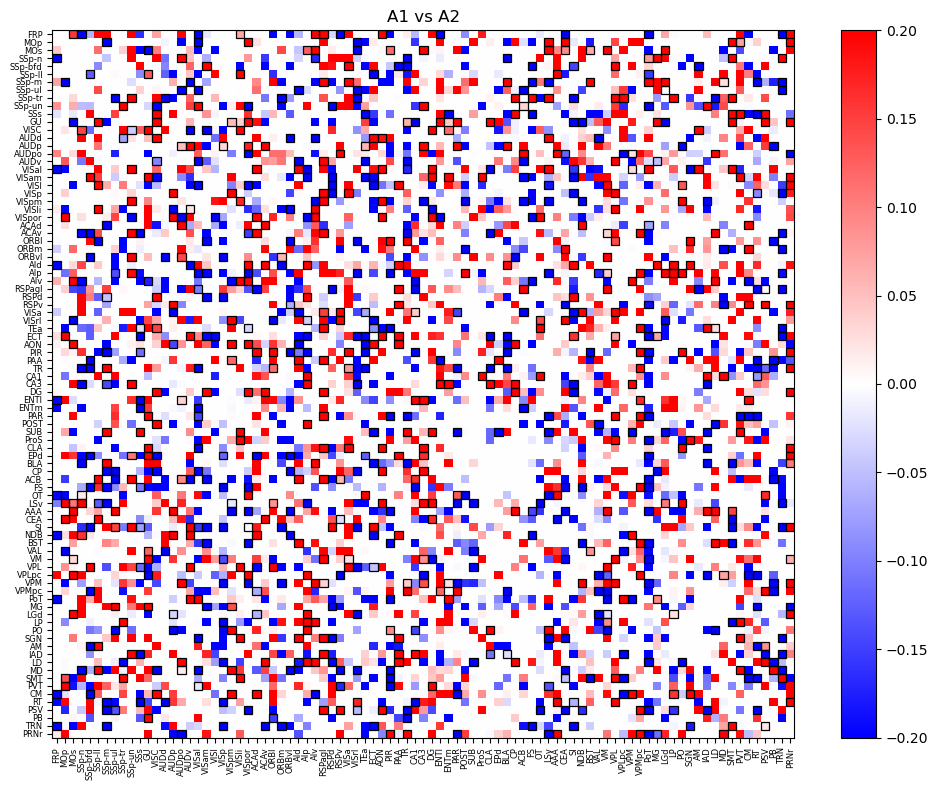

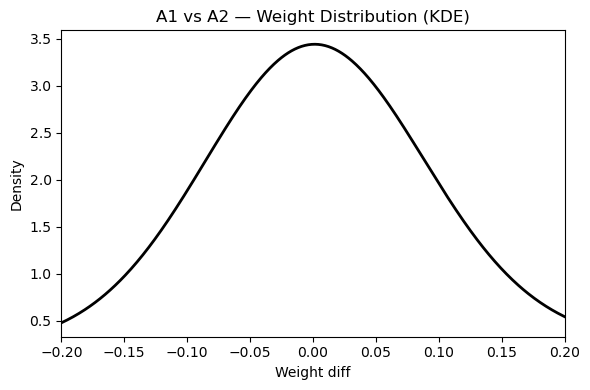

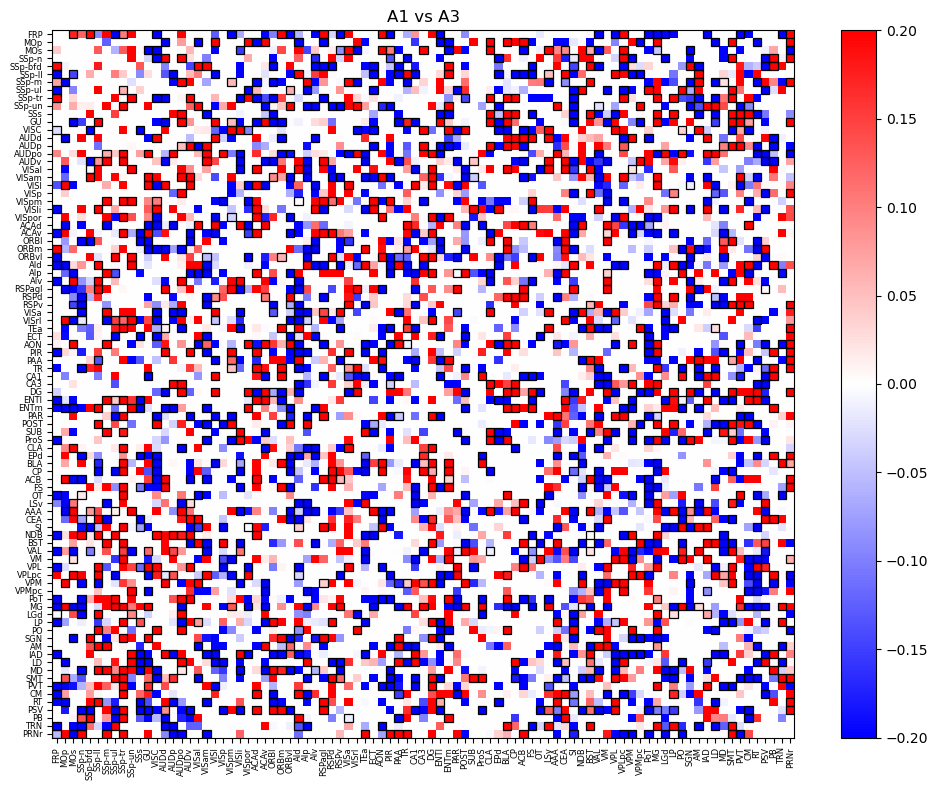

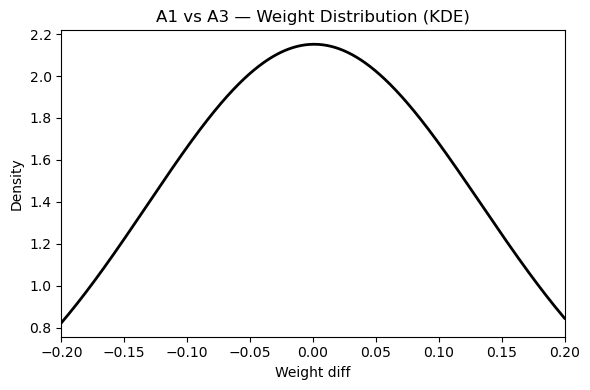

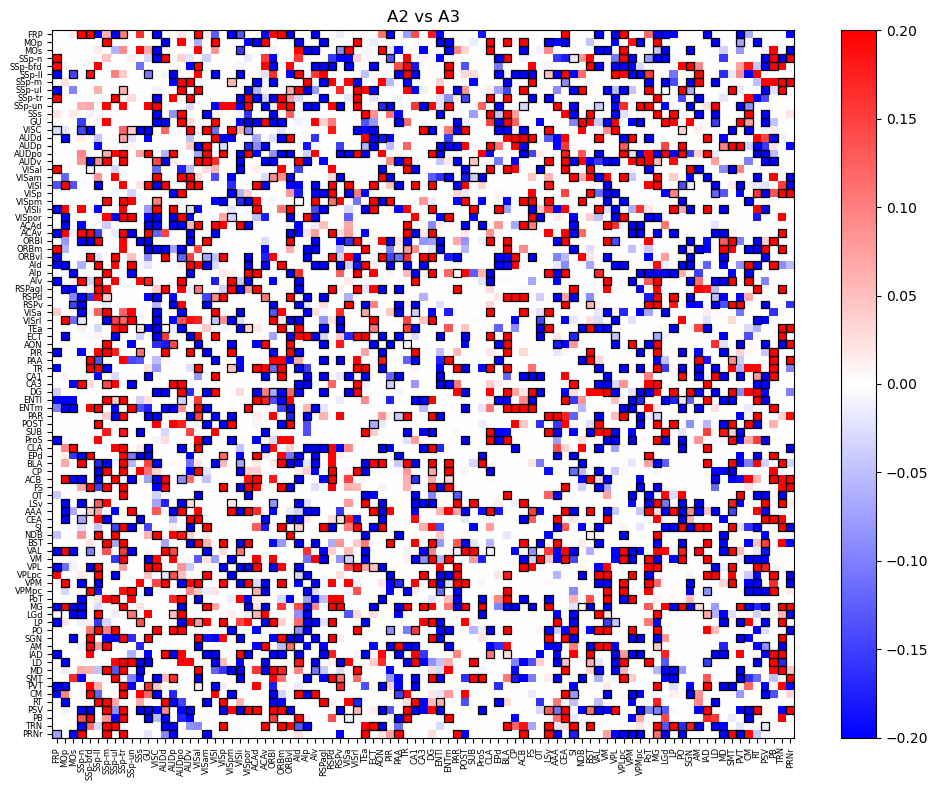

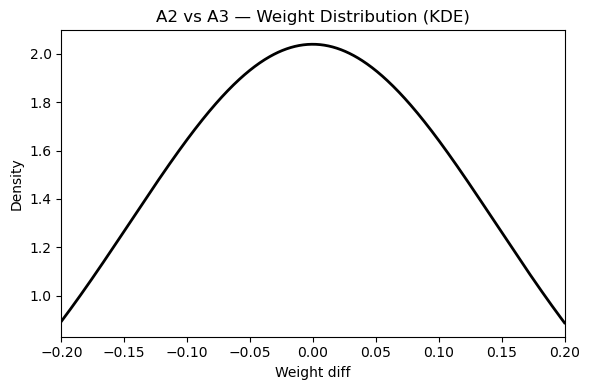

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.stats import gaussian_kde


def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


def plot_heatmap_only(adj1, adj2, diff_mat, labels, title,
                      vmin=None, vmax=None, savepdf=None):

    n = diff_mat.shape[0]
    if vmin is None:
        vmin = diff_mat.min()
    if vmax is None:
        vmax = diff_mat.max()

    fig = plt.figure(figsize=(10, 8))
    x = np.arange(n + 1)
    y = np.arange(n + 1)

    plt.pcolormesh(
        x, y, diff_mat,
        cmap='bwr',
        vmin=vmin, vmax=vmax,
        shading='flat'
    )
    plt.colorbar()
    plt.title(title)

    plt.xticks(np.arange(n) + 0.5, labels, rotation=90, fontsize=6)
    plt.yticks(np.arange(n) + 0.5, labels, fontsize=6)

    opposite = (adj1 * adj2) < 0
    ax = plt.gca()
    for i in range(n):
        for j in range(n):
            if opposite[i, j]:
                ax.add_patch(
                    patches.Rectangle(
                        (j, i), 1, 1,
                        linewidth=0.9,
                        edgecolor="black",
                        facecolor="none"
                    )
                )

    plt.gca().invert_yaxis()
    plt.tight_layout()

    if savepdf is not None:
        fig.savefig(savepdf, format="pdf", dpi=300, bbox_inches="tight")

    plt.show()


def plot_kde_only(diff_mat, title, dist_xlim=None, kde_bw=0.3, savepdf=None):

    diff_vals = diff_mat.flatten()
    kde = gaussian_kde(diff_vals, bw_method=kde_bw)

    if dist_xlim is None:
        xmin, xmax = diff_vals.min(), diff_vals.max()
    else:
        xmin, xmax = dist_xlim

    xs = np.linspace(xmin, xmax, 600)
    ys = kde(xs)

    fig = plt.figure(figsize=(6, 4))
    plt.plot(xs, ys, color="black", linewidth=2)
    plt.title(f"{title} — Weight Distribution (KDE)")
    plt.xlabel("Weight diff")
    plt.ylabel("Density")

    if dist_xlim is not None:
        plt.xlim(dist_xlim)

    plt.tight_layout()

    if savepdf is not None:
        fig.savefig(savepdf, format="pdf", dpi=300, bbox_inches="tight")

    plt.show()



A1, L1 = load_mean_adj(
    './train_with_random_SC_seed22/result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0_seed22/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A2, L2 = load_mean_adj(
    './train_with_random_SC_seed22/result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0_seed22/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A3, L3 = load_mean_adj(
    './train_with_random_SC_seed22/result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5_seed22/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

D12 = A2 - A1
D13 = A3 - A1
D23 = A3 - A2


plot_heatmap_only(
    A1, A2, D12, L1,
    "A1 vs A2",
    vmin=-0.2, vmax=0.2,
    savepdf="./train_with_random_SC_seed22/result/fig/A1_vs_A2_heatmap.pdf"
)
plot_kde_only(
    D12, "A1 vs A2",
    dist_xlim=(-0.2, 0.2),
    savepdf="./train_with_random_SC_seed22/result/fig/A1_vs_A2_KDE.pdf"
)


plot_heatmap_only(
    A1, A3, D13, L1,
    "A1 vs A3",
    vmin=-0.2, vmax=0.2,
    savepdf="./train_with_random_SC_seed22/result/fig/A1_vs_A3_heatmap.pdf"
)
plot_kde_only(
    D13, "A1 vs A3",
    dist_xlim=(-0.2, 0.2),
    savepdf="./train_with_random_SC_seed22/result/fig/A1_vs_A3_KDE.pdf"
)


plot_heatmap_only(
    A2, A3, D23, L2,
    "A2 vs A3",
    vmin=-0.2, vmax=0.2,
    savepdf="./train_with_random_SC_seed22/result/fig/A2_vs_A3_heatmap.pdf"
)
plot_kde_only(
    D23, "A2 vs A3",
    dist_xlim=(-0.2, 0.2),
    savepdf="./train_with_random_SC_seed22/result/fig/A2_vs_A3_KDE.pdf"
)


In [2]:
import numpy as np
import pandas as pd
import networkx as nx


def build_graph_from_adj(A):
    G = nx.DiGraph()
    n = A.shape[0]

    for i in range(n):
        for j in range(n):
            if i == j or A[i, j] == 0:
                continue

            weight = float(abs(A[i, j]))
            G.add_edge(i, j, weight=weight)

    return G


def centrality_diff(Aa, Ab):
    G1 = build_graph_from_adj(Aa)
    G2 = build_graph_from_adj(Ab)

    n = Aa.shape[0]

    bc1 = nx.betweenness_centrality(G1, weight="weight")
    bc2 = nx.betweenness_centrality(G2, weight="weight")

    diff = np.zeros(n)

    for i in range(n):
        diff[i] = bc1.get(i, 0.0) - bc2.get(i, 0.0)

    return diff


def compute_change_hubs(A1, A2, A3, labels):

    n = A1.shape[0]

    D12 = A2 - A1
    D13 = A3 - A1
    D23 = A3 - A2

    NodeChange_12 = np.sum(np.abs(D12), axis=1)
    NodeChange_13 = np.sum(np.abs(D13), axis=1)
    NodeChange_23 = np.sum(np.abs(D23), axis=1)

    th12 = np.percentile(np.abs(D12), 95)
    th13 = np.percentile(np.abs(D13), 95)
    th23 = np.percentile(np.abs(D23), 95)

    SigEdges_12 = np.sum(np.abs(D12) > th12, axis=1)
    SigEdges_13 = np.sum(np.abs(D13) > th13, axis=1)
    SigEdges_23 = np.sum(np.abs(D23) > th23, axis=1)

    BC_12 = centrality_diff(A2, A1)
    BC_13 = centrality_diff(A3, A1)
    BC_23 = centrality_diff(A3, A2)

    def normalize(x):
        return (x - x.min()) / (x.max() - x.min() + 1e-9)

    Hub_12 = 1/3 * normalize(NodeChange_12) + \
             1/3 * normalize(SigEdges_12) + \
             1/3 * normalize(np.abs(BC_12))

    Hub_13 = 1/3 * normalize(NodeChange_13) + \
             1/3 * normalize(SigEdges_13) + \
             1/3 * normalize(np.abs(BC_13))

    Hub_23 = 1/3 * normalize(NodeChange_23) + \
             1/3 * normalize(SigEdges_23) + \
             1/3 * normalize(np.abs(BC_23))

    df = pd.DataFrame({
        "Region": labels,

        "NodeChange_12": NodeChange_12,
        "NodeChange_13": NodeChange_13,
        "NodeChange_23": NodeChange_23,

        "SigEdges_12": SigEdges_12,
        "SigEdges_13": SigEdges_13,
        "SigEdges_23": SigEdges_23,

        "BC_Δ12": BC_12,
        "BC_Δ13": BC_13,
        "BC_Δ23": BC_23,

        "HubScore_12": Hub_12,
        "HubScore_13": Hub_13,
        "HubScore_23": Hub_23
    })

    return df.sort_values("HubScore_12", ascending=False)

In [3]:
!which python

/home/ylx/anaconda3/envs/ibl_bwm/bin/python


In [4]:
df_hub = compute_change_hubs(A1, A2, A3, L1)
df_hub.head(10)

,Region,NodeChange_12,NodeChange_13,NodeChange_23,SigEdges_12,SigEdges_13,SigEdges_23,BC_Δ12,BC_Δ13,BC_Δ23,HubScore_12,HubScore_13,HubScore_23
59,LSv,17.334698,15.460702,23.618462,11,3,8,0.073015,0.074190,0.001176,0.916779,0.395164,0.398699
11,GU,16.746871,24.020426,22.571790,10,5,5,-0.060475,-0.028997,0.031479,0.827202,0.409086,0.407738
85,PSV,16.269883,26.982786,34.642440,10,5,9,0.033699,-0.008882,-0.042581,0.722236,0.380752,0.714656
38,ECT,17.221967,14.972700,21.208359,11,4,6,0.017111,0.033699,0.016588,0.722150,0.291280,0.367343
42,TR,14.850675,19.577508,26.233751,8,6,8,-0.060214,-0.060606,-0.000392,0.713055,0.483843,0.423651
60,AAA,16.730745,25.658270,30.771995,9,8,8,-0.029389,-0.026515,0.002874,0.689963,0.503642,0.482197
21,VISpm,14.001719,18.778306,23.460507,8,5,7,0.057602,0.081505,0.023903,0.680536,0.511861,0.453873
23,VISpor,12.766600,15.769339,18.232473,9,6,4,-0.053945,-0.039577,0.014368,0.664019,0.374344,0.259932
25,ACAv,13.131545,23.308293,23.749636,9,4,5,0.045324,-0.008098,-0.053422,0.644621,0.308030,0.507468
30,AIp,16.375266,24.736380,20.746411,7,4,5,-0.024556,-0.025209,-0.000653,0.602933,0.377802,0.265808


In [5]:
df_hub.sort_values("HubScore_12", ascending=False)[['Region', 'HubScore_12']] \
      .to_csv("./train_with_random_SC_seed22/HubScore_12_sorted.csv", index=False)

df_hub.sort_values("HubScore_13", ascending=False)[['Region', 'HubScore_13']] \
      .to_csv("./train_with_random_SC_seed22/HubScore_13_sorted.csv", index=False)

df_hub.sort_values("HubScore_23", ascending=False)[['Region', 'HubScore_23']] \
      .to_csv("./train_with_random_SC_seed22/HubScore_23_sorted.csv", index=False)

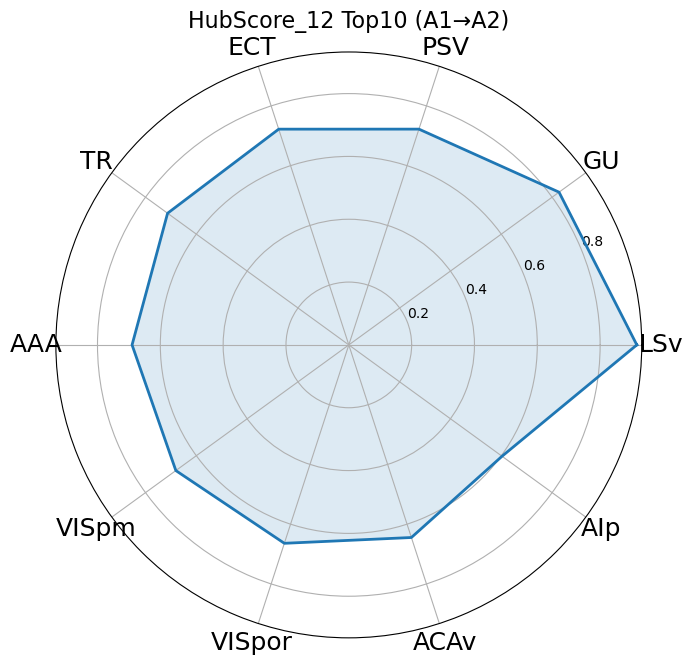

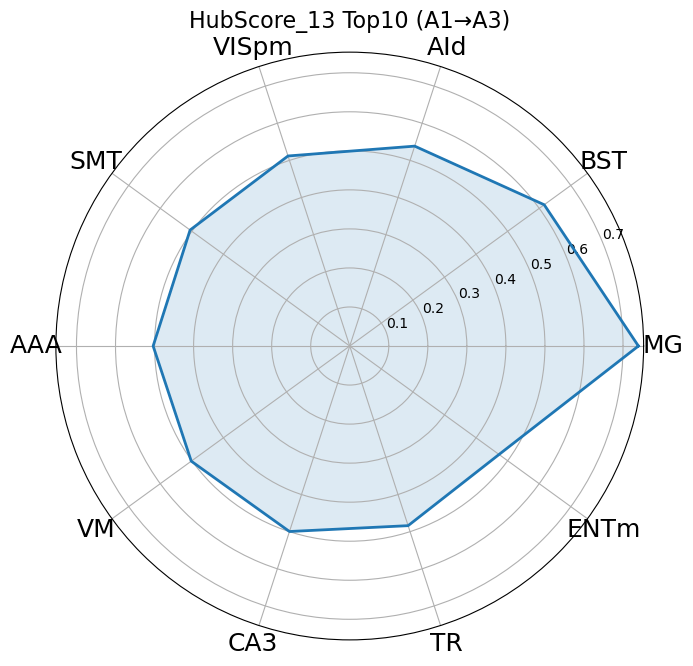

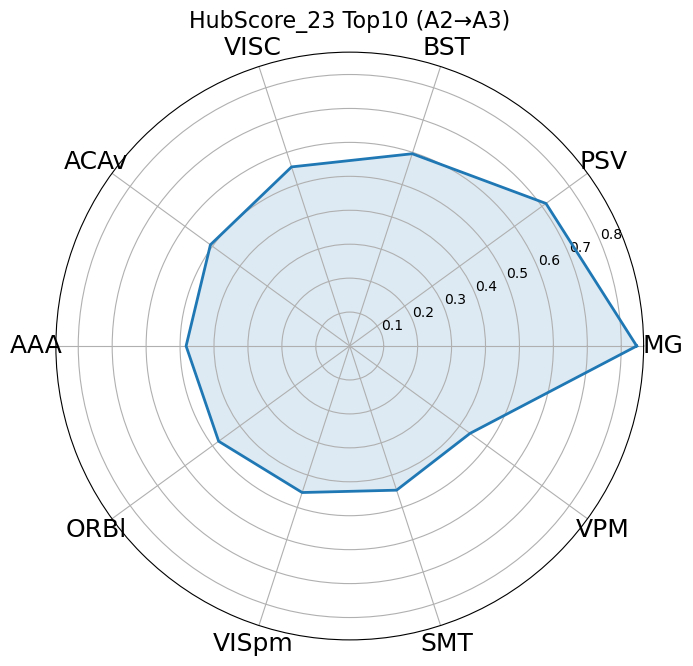

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def draw_radar_single(regions, values, title, fontsize_labels=12, savepdf=None):
    N = len(regions)
    angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
    angles += angles[:1]
    v = np.concatenate([values, [values[0]]])

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'polar': True})

    ax.plot(angles, v, linewidth=2)
    ax.fill(angles, v, alpha=0.15)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(regions, fontsize=fontsize_labels)
    ax.set_title(title, fontsize=16)
    ax.grid(True)

    plt.tight_layout()

    if savepdf is not None:
        plt.savefig(savepdf, dpi=300, format="pdf")
    plt.show()
    plt.close(fig)


def plot_radar_separate(df_hub, fontsize_labels=12, outdir="./train_with_random_SC_seed22/result/fig/"):
    top12 = df_hub.sort_values("HubScore_12", ascending=False).head(10)
    top13 = df_hub.sort_values("HubScore_13", ascending=False).head(10)
    top23 = df_hub.sort_values("HubScore_23", ascending=False).head(10)

    draw_radar_single(
        top12["Region"].values,
        top12["HubScore_12"].values,
        "HubScore_12 Top10 (A1→A2)",
        fontsize_labels,
        savepdf=f"{outdir}/radar_A1_A2.pdf"
    )

    draw_radar_single(
        top13["Region"].values,
        top13["HubScore_13"].values,
        "HubScore_13 Top10 (A1→A3)",
        fontsize_labels,
        savepdf=f"{outdir}/radar_A1_A3.pdf"
    )

    draw_radar_single(
        top23["Region"].values,
        top23["HubScore_23"].values,
        "HubScore_23 Top10 (A2→A3)",
        fontsize_labels,
        savepdf=f"{outdir}/radar_A2_A3.pdf"
    )


plot_radar_separate(df_hub, fontsize_labels=18)

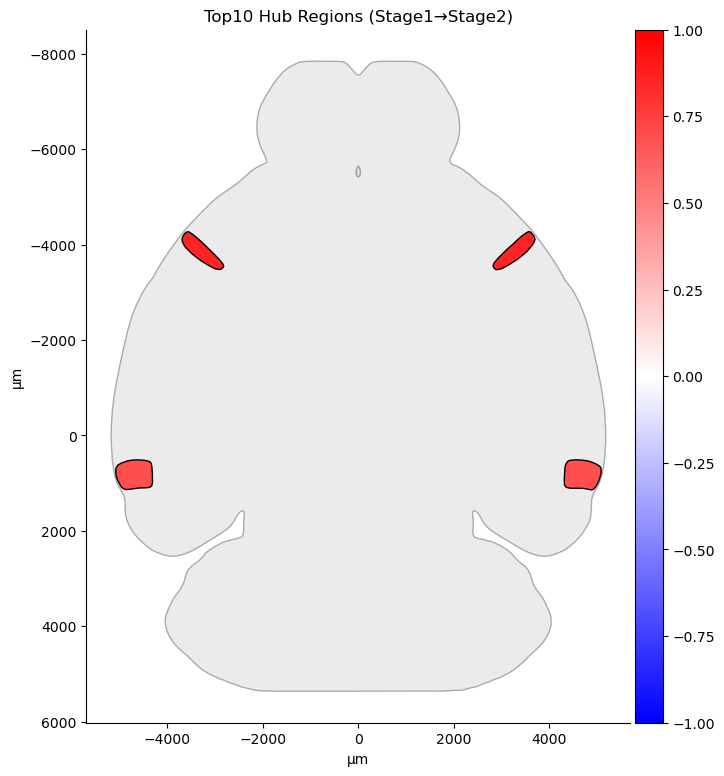

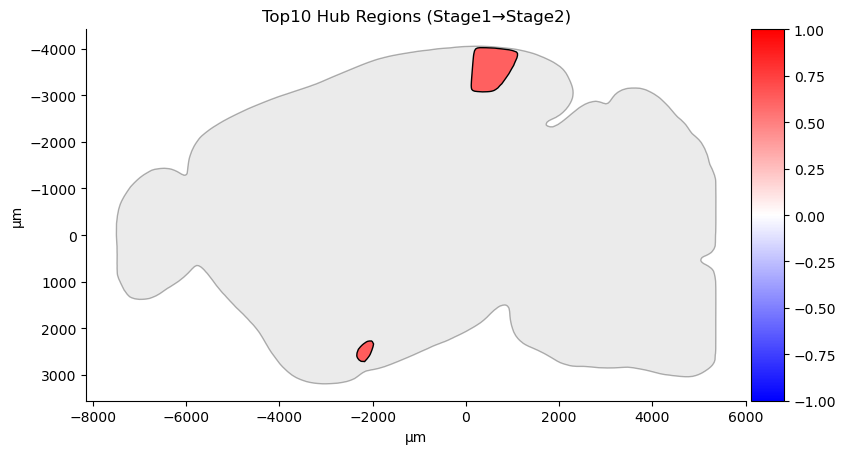

In [7]:
import numpy as np
import brainrender as br
import brainglobe_heatmap as bgh

top12 = df_hub.sort_values("HubScore_12", ascending=False).head(10)
regions = top12["Region"].values
scores = top12["HubScore_12"].values

def normalize_to_range(values, new_min=0.5, new_max=1):
    v = np.array(values)
    old_min, old_max = v.min(), v.max()
    scaled = (v - old_min) / (old_max - old_min + 1e-9)
    scaled = scaled * (new_max - new_min) + new_min
    return scaled

norm_scores = normalize_to_range(scores)
region_value_dict = dict(zip(regions, norm_scores))

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage2)"
).plot(size=(500, 350), axes=False)

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="sagittal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage2)"
).plot(size=(500, 350), axes=False)

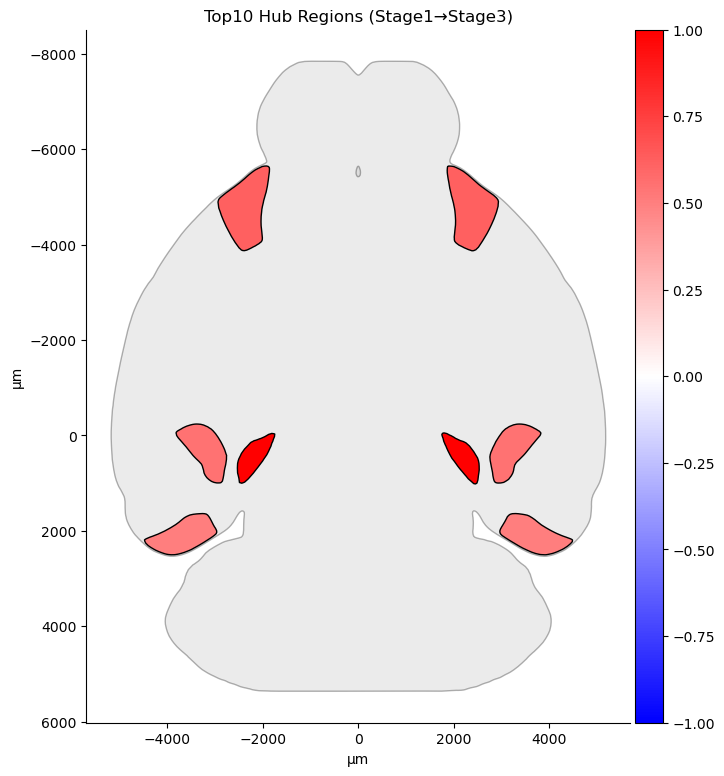

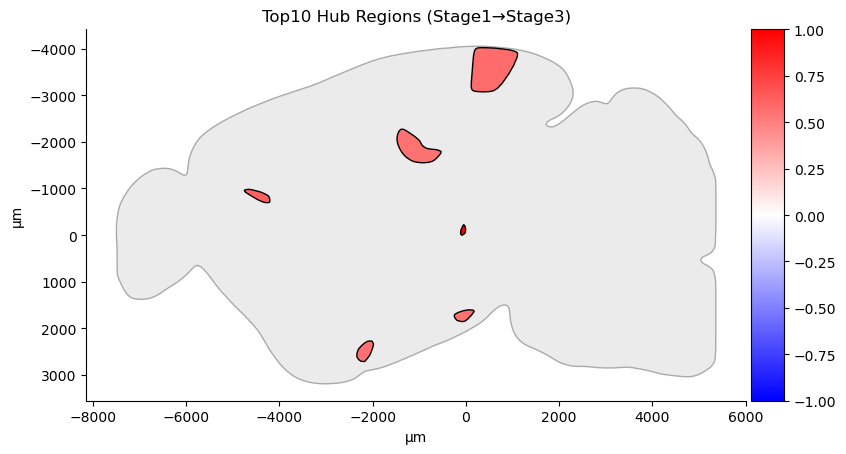

In [8]:
import numpy as np
import brainrender as br
import brainglobe_heatmap as bgh

top13 = df_hub.sort_values("HubScore_13", ascending=False).head(10)
regions = top13["Region"].values
scores = top13["HubScore_13"].values

def normalize_to_range(values, new_min=0.5, new_max=1):
    v = np.array(values)
    old_min, old_max = v.min(), v.max()
    scaled = (v - old_min) / (old_max - old_min + 1e-9)
    scaled = scaled * (new_max - new_min) + new_min
    return scaled

norm_scores = normalize_to_range(scores)
region_value_dict = dict(zip(regions, norm_scores))

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage3)"
).plot(size=(500, 350), axes=False)

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="sagittal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage3)"
).plot(size=(500, 350), axes=False)


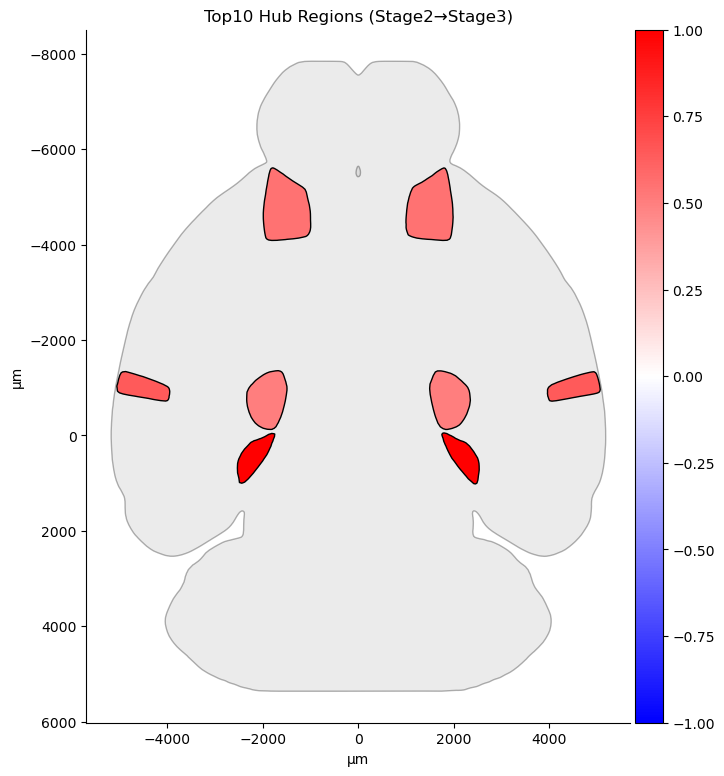

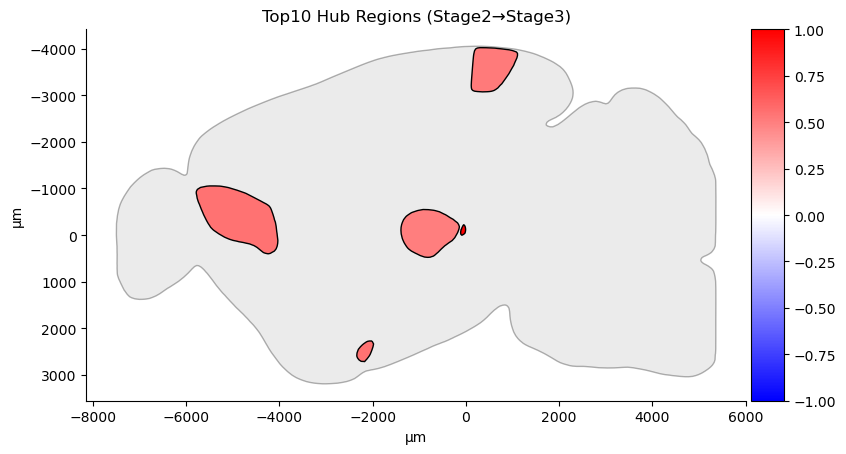

In [9]:
import numpy as np
import brainrender as br
import brainglobe_heatmap as bgh

top23 = df_hub.sort_values("HubScore_23", ascending=False).head(10)
regions = top23["Region"].values
scores = top23["HubScore_23"].values

def normalize_to_range(values, new_min=0.5, new_max=1):
    v = np.array(values)
    old_min, old_max = v.min(), v.max()
    scaled = (v - old_min) / (old_max - old_min + 1e-9)
    scaled = scaled * (new_max - new_min) + new_min
    return scaled

norm_scores = normalize_to_range(scores)
region_value_dict = dict(zip(regions, norm_scores))

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage2→Stage3)"
).plot(size=(500, 350), axes=False)

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="sagittal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage2→Stage3)"
).plot(size=(500, 350), axes=False)


In [10]:
import numpy as np,networkx as nx,matplotlib.pyplot as plt,matplotlib.patheffects as pe

def adjust_labels_smart(pos,labels,ax,fontsize=9,push_strength=.02,iterations=80):
    P={k:np.array(v,float) for k,v in pos.items()}; r=ax.figure.canvas.get_renderer()
    for _ in range(iterations):
        I=list(P.items()); B={}
        for i,p in I:
            t=ax.text(*p,labels[i],fontsize=fontsize); B[i]=t.get_window_extent(r).expanded(1.1,1.1); t.remove()
        ch=False
        for a in range(len(I)):
            i,p=I[a]
            for b in range(a+1,len(I)):
                j,q=I[b]
                if B[i].overlaps(B[j]):
                    v=p-q
                    if np.linalg.norm(v)<1e-9:v=np.random.randn(2)
                    v/=np.linalg.norm(v); P[i]+=push_strength*v; P[j]-=push_strength*v; ch=True
        if not ch:break
    return P

def draw_label(ax,x,y,text,fontsize=9,alpha_box=.3):
    t=ax.text(x,y,text,fontsize=fontsize,fontweight="bold",ha="center",va="center",
              bbox=dict(boxstyle="round,pad=.25",fc=(1,1,1,alpha_box),ec="none"))
    t.set_path_effects([pe.Stroke(linewidth=3,foreground="white"),pe.Normal()])

def plot_explainable_network(diff_mat,labels,df_hub,score_col,top_k=150,title="Network Explanation",savepdf=None):
    labels=np.array(labels); H=df_hub.set_index("Region").loc[labels,score_col].values; n=len(labels)
    G=nx.DiGraph(); G.add_nodes_from(range(n))
    E=sorted([(i,j,abs(diff_mat[i,j]),diff_mat[i,j]) for i in range(n) for j in range(n) if i!=j],
             key=lambda x:x[2],reverse=True)[:top_k]
    for i,j,a,v in E:G.add_edge(i,j,weight=a,sign=np.sign(v))

    pos=nx.spring_layout(G,seed=1,k=.3); fig,ax=plt.subplots(figsize=(14,12))
    S=2200*(H-H.min())/(H.max()-H.min()+1e-9)
    nx.draw_networkx_nodes(G,pos,ax=ax,node_size=S,node_color=H,cmap="Purples",vmin=0,vmax=1)

    for u,v,d in G.edges(data=True):
        rad=(.1 if u<v else -.1) if G.has_edge(v,u) else .03
        nx.draw_networkx_edges(G,pos,ax=ax,edgelist=[(u,v)],width=d["weight"]*5,
            edge_color=["red" if d["sign"]>0 else "blue"],alpha=.55,arrows=True,
            arrowstyle="-|>",arrowsize=14,connectionstyle=f"arc3,rad={rad}",
            min_source_margin=5,min_target_margin=8)

    for i,(x,y) in adjust_labels_smart(pos,labels,ax).items():draw_label(ax,x,y,labels[i])

    ax.set_title(title,fontsize=18); ax.axis("off")
    sm=plt.cm.ScalarMappable(cmap="Purples",norm=plt.Normalize(0,1)); sm.set_array([])
    fig.colorbar(sm,ax=ax,label=score_col,fraction=.03,pad=.04)

    if savepdf:plt.savefig(savepdf,dpi=300,format="png",bbox_inches="tight")
    plt.show()

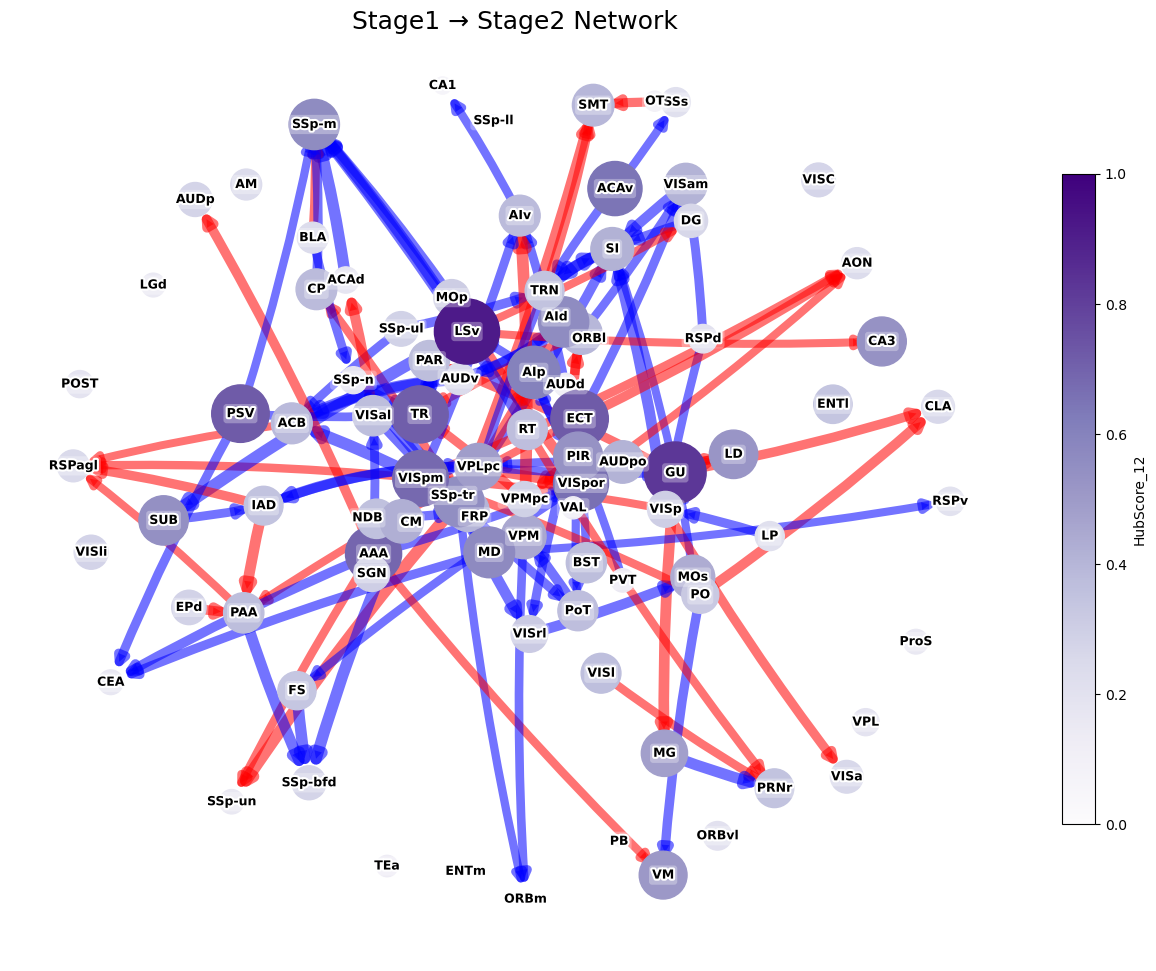

In [11]:
plot_explainable_network(
    D12, L1, df_hub, "HubScore_12",
    top_k=120,
    title="Stage1 → Stage2 Network",
    savepdf="./train_with_random_SC_seed22/result/fig/network_stage12.png"
)

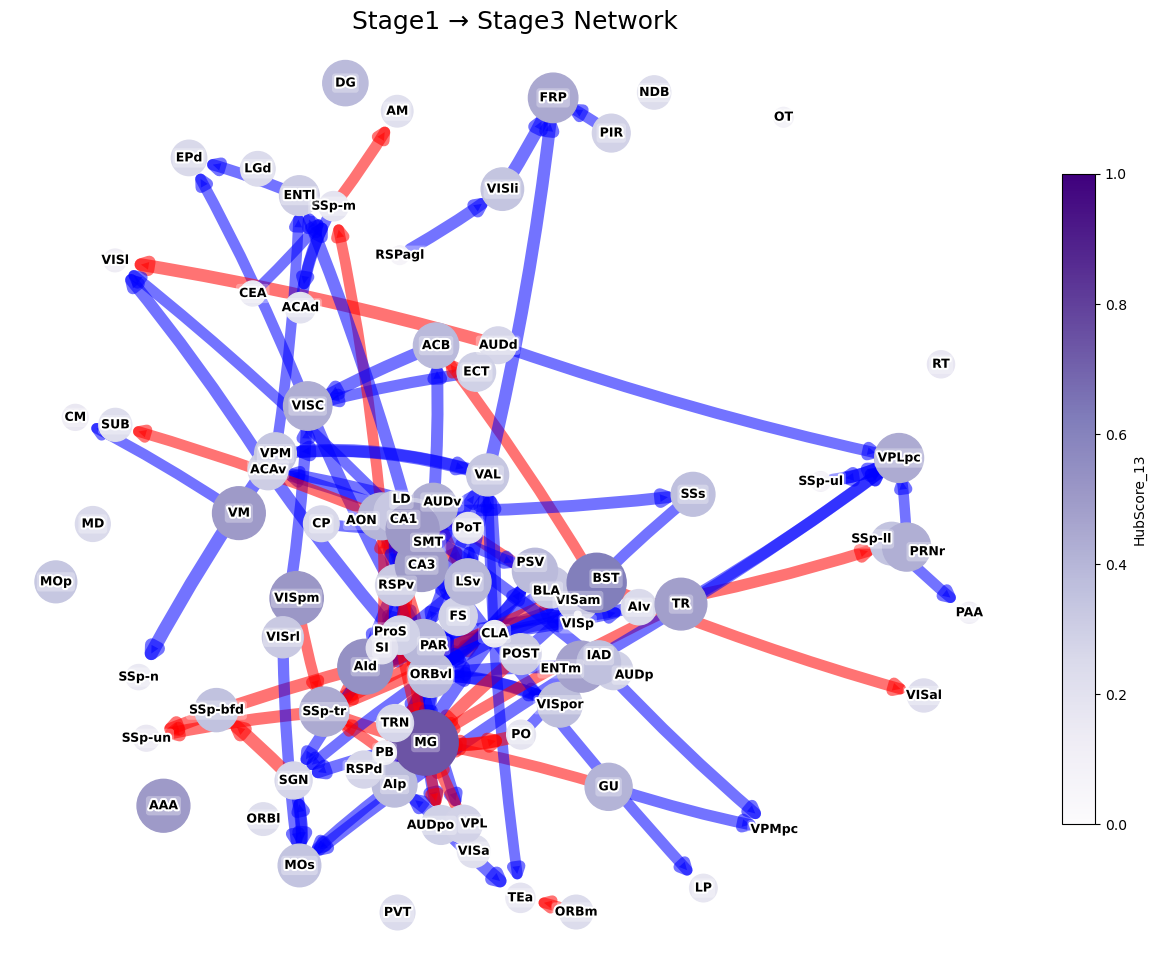

In [12]:
plot_explainable_network(
    D13, L1, df_hub, "HubScore_13",
    top_k=120,
    title="Stage1 → Stage3 Network",
    savepdf="./train_with_random_SC_seed22/result/fig/network_stage13.png"
)

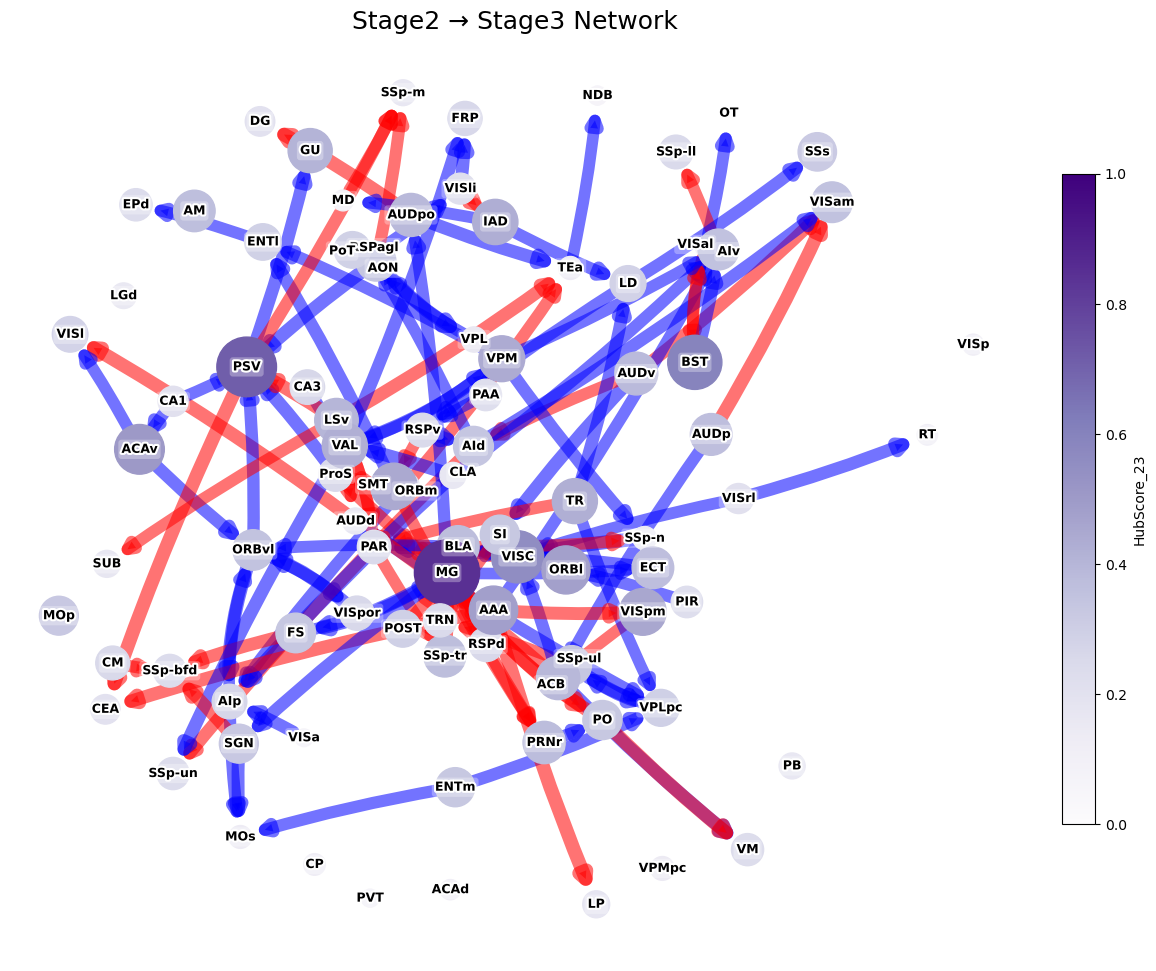

In [13]:
plot_explainable_network(
    D23, L2, df_hub, "HubScore_23",
    top_k=120,
    title="Stage2 → Stage3 Network",
    savepdf="./train_with_random_SC_seed22/result/fig/network_stage23.png"
)

  System Comparison  MeanRate
Movement       II−I  0.136818
Movement      III−I  0.160627
Movement     III−II  0.140334
Feedback       II−I  0.320162
Feedback      III−I  0.318812
Feedback     III−II  0.446725


/tmp/ipykernel_1454641/2093069965.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=.6)


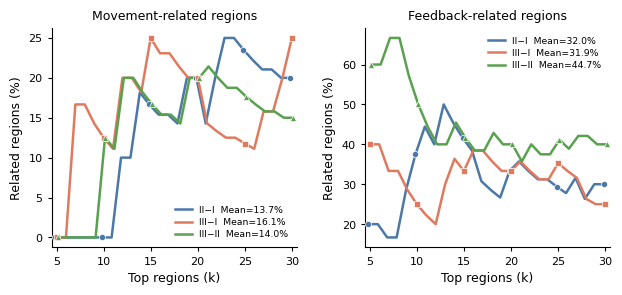

In [14]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests

FILES={"II−I":"./train_with_random_SC_seed22/HubScore_12_sorted.csv",
       "III−I":"./train_with_random_SC_seed22/HubScore_13_sorted.csv",
       "III−II":"./train_with_random_SC_seed22/HubScore_23_sorted.csv"}

SETS={
    "Movement":{"MOp","MOs","SSp-bfd","SSp-ll","SSp-m","SSp-n","SSp-tr","SSp-ul","SSp-un","SSs",
                "VPM","VPL","PO","VAL","VM","CP","PRNr"},
    "Feedback":{"VISC","GU","AIp","AId","AIv","VPMpc","VPLpc","CP","MD",
                "ACAd","ACAv","ORBvl","ORBm","ORBl","MG", "AUDp", "AUDd", "AUDv", "AUDpo"}
}

D={}
for k,f in FILES.items():
    x=pd.read_csv(f,header=None,skiprows=1,names=["Region","Score"])
    x.Score=pd.to_numeric(x.Score,errors="coerce")
    D[k]=x.dropna().sort_values("Score",ascending=False).drop_duplicates("Region")

U=set.intersection(*[set(x.Region) for x in D.values()])
D={k:x[x.Region.isin(U)].reset_index(drop=True) for k,x in D.items()}
N,MAXK=len(U),min(30,len(U))

def hitrate(r,ref):
    ref=ref&U
    if not len(r) or not len(ref): return 0,np.nan,np.nan
    h=len(r&ref)
    return h,h/len(r),hypergeom.sf(h-1,N,len(ref),len(r))

R=[]
for top in range(5,MAXK+1):
    S={k:set(x.Region[:top]) for k,x in D.items()}
    C=set.intersection(*S.values())
    for sys,ref in SETS.items():
        for comp,s in S.items():
            r=s-C; h,rate,p=hitrate(r,ref)
            R.append([top,sys,comp,len(r),len(C),h,rate,p])

res=pd.DataFrame(R,columns=["TopK","System","Comparison","N_regions","CommonN","Hits","HitRate","P"])
res["FDR"]=np.nan
m=res.P.notna()
res.loc[m,"FDR"]=multipletests(res.loc[m,"P"],method="fdr_bh")[1]
res.to_csv("stage_specific_hub_hitrate_top30.csv",index=False)

A=[]
for sys in SETS:
    p=res[res.System==sys].pivot(index="TopK",columns="Comparison",values="HitRate").dropna(subset=list(FILES))
    if len(p)<2: continue
    x=p.index.values.astype(float)
    for comp in FILES:
        y=p[comp].values.astype(float)
        a=np.trapz(y,x)
        A.append([sys,comp,a/(x[-1]-x[0])])

auc=pd.DataFrame(A,columns=["System","Comparison","MeanRate"])
auc.to_csv("stage_specific_hub_hitrate_AUC.csv",index=False)
print(auc.to_string(index=False))

plt.rcParams.update({
    "font.size":8,
    "axes.labelsize":9,
    "axes.titlesize":9,
    "xtick.labelsize":8,
    "ytick.labelsize":8,
    "axes.linewidth":.8,
    "pdf.fonttype":42,
    "ps.fonttype":42
})

COL={"II−I":"#4C78A8","III−I":"#E07A5F","III−II":"#59A14F"}
OFF={"II−I":-.15,"III−I":0,"III−II":.15}
MARK={"II−I":"o","III−I":"s","III−II":"^"}

fig,axs=plt.subplots(
    1,2,figsize=(7.2,2.85),
    sharey=False,
    gridspec_kw={"wspace":.28}
)

for ax,(sys,ref) in zip(axs,SETS.items()):
    z=res[res.System==sys]

    for comp in FILES:
        q=z[z.Comparison==comp].sort_values("TopK")
        mean=auc[(auc.System==sys)&(auc.Comparison==comp)].MeanRate.iloc[0]*100
        x=q.TopK+OFF[comp]

        ax.plot(
            x,q.HitRate*100,
            lw=1.8,color=COL[comp],
            label=f"{comp}  Mean={mean:.1f}%"
        )

        m=q.TopK.isin([5,10,15,20,25,30])
        ax.scatter(
            x[m],q.loc[m,"HitRate"]*100,
            s=20,marker=MARK[comp],
            color=COL[comp],
            edgecolor="white",linewidth=.5,
            zorder=3
        )

    ax.set(
        xlabel="Top regions (k)",
        ylabel="Related regions (%)",
        title=f"{sys}-related regions",
        xlim=(4.5,30.5),
        xticks=[5,10,15,20,25,30]
    )

    ax.spines[["top","right"]].set_visible(False)
    ax.tick_params(width=.8,length=3)
    ax.legend(
        frameon=False,
        fontsize=6.7,
        handlelength=1.8,
        labelspacing=.35
    )

plt.tight_layout(pad=.6)

plt.savefig("./train_with_random_SC_seed22/stage_specific_hub_hitrate.pdf",bbox_inches="tight")
plt.savefig("./train_with_random_SC_seed22/stage_specific_hub_hitrate.png",dpi=600,bbox_inches="tight")

plt.show()

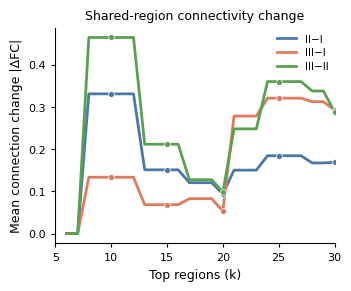

In [15]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt

FILES={"II−I":"./train_with_random_SC_seed22/HubScore_12_sorted.csv",
       "III−I":"./train_with_random_SC_seed22/HubScore_13_sorted.csv",
       "III−II":"./train_with_random_SC_seed22/HubScore_23_sorted.csv"}

D={}
for k,f in FILES.items():
    x=pd.read_csv(f,header=None,skiprows=1,names=["Region","Score"])
    x.Score=pd.to_numeric(x.Score,errors="coerce")
    D[k]=x.dropna().sort_values("Score",ascending=False).drop_duplicates("Region")

L=np.asarray(L1)
PAIRS={"II−I":(A1,A2),"III−I":(A1,A3),"III−II":(A2,A3)}

U=set(L)&set.intersection(*[set(x.Region) for x in D.values()])
D={k:x[x.Region.isin(U)].reset_index(drop=True) for k,x in D.items()}
idx={r:i for i,r in enumerate(L)}

R=[]
for top in range(5,min(30,len(U))+1):
    S={k:set(x.Region[:top]) for k,x in D.items()}
    C=set.intersection(*S.values())
    if not C: continue

    ii=[idx[r] for r in C]

    for comp,(A,B) in PAIRS.items():
        d=(B-A)[np.ix_(ii,ii)]
        R.append([top,comp,len(C),np.mean(np.abs(d))])

res=pd.DataFrame(R,columns=["TopK","Comparison","N_shared","MeanAbsDeltaFC"])
res.to_csv("shared_region_FC_change.csv",index=False)

# ================= PLOT =================
plt.rcParams.update({
    "font.size":8,
    "axes.labelsize":9,
    "xtick.labelsize":8,
    "ytick.labelsize":8,
    "axes.linewidth":.8,
    "pdf.fonttype":42,
    "ps.fonttype":42
})

COL={"II−I":"#4C78A8",
     "III−I":"#E07A5F",
     "III−II":"#59A14F"}

fig,ax=plt.subplots(figsize=(3.45,2.85))

for comp in PAIRS:
    q=res[res.Comparison==comp].sort_values("TopK")

    ax.plot(q.TopK,q.MeanAbsDeltaFC,
            lw=2,color=COL[comp],label=comp)

    q5=q[q.TopK.isin([5,10,15,20,25,30])]
    ax.scatter(q5.TopK,q5.MeanAbsDeltaFC,
               s=18,color=COL[comp],edgecolor="white",
               linewidth=.5,zorder=3)

ax.set(
    xlabel="Top regions (k)",
    ylabel="Mean connection change |ΔFC|",
    xlim=(5,30),
    xticks=[5,10,15,20,25,30]
)

ax.spines[["top","right"]].set_visible(False)
ax.spines[["left","bottom"]].set_linewidth(.8)
ax.tick_params(width=.8,length=3)
ax.set_title("Shared-region connectivity change",fontsize=9,pad=6)
ax.legend(
    frameon=False,
    fontsize=7.5,
    handlelength=1.8,
    labelspacing=.35,
    borderaxespad=.2
)

plt.tight_layout(pad=.6)

plt.savefig("./train_with_random_SC_seed22/shared_region_FC_change.pdf",bbox_inches="tight")
plt.savefig("./train_with_random_SC_seed22/shared_region_FC_change.png",dpi=600,bbox_inches="tight")
plt.show()